# 09 · The project data (work package 1)

**Work package 1** of the [implementation plan](../../research/implementation_plan.md): turn the 12 downloaded
weeks of Uniswap-style swaps into validated *trade legs*, the working data of every later notebook.

This notebook

1. loads `data/project/`, built by `uv run python src/scripts/token_data.py` (its printed log is shown below),
2. shows the data-quality checks for every week,
3. shows which base currencies were removed, and why,
4. checks that the data covers the plan's dates, and
5. recomputes the descriptive statistics of the project plan (its Table 4) on the 12 weeks.

**No model is fitted here.** Daily counts of the test period are shown because validating every week is part of
work package 1; nothing else about the test period is looked at.

## Setup

The reusable code lives in `src/scripts/`; this notebook only calls it.

In [1]:
import json
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import pandas as pd

import plots
import protocol as pc
import token_data as td

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. How the working data was built

`token_data.py` does, in order:

1. load the chunks of the project's blocks (it stops if any block range is missing),
2. validate each batch of about one week and reduce every transaction to the tokens its signer finally bought and sold,
3. decide the base currencies on the burn-in period (tokens traded by more than 10% of its users),
4. remove them, replace addresses by integer ids, keep only legs from 18 June to 10 September 00:00 UTC, and write the files.

Building takes several minutes and is done once from the command line; this is its log.

In [2]:
print((td.PROJECT_DIR.parents[1] / "logs" / "build_project_data.log").read_text().split("\n\t")[0])

Project blocks 25,340,000 to 25,948,799: 609 chunk files, no gaps.
  batch  1: 1,265,288 swaps -> 1,877,098 legs (17 Jun 21:36 to 24 Jun 20:56)
  batch  2: 1,340,552 swaps -> 1,966,443 legs (24 Jun 20:57 to 01 Jul 20:17)
  batch  3: 1,296,100 swaps -> 1,904,791 legs (01 Jul 20:17 to 08 Jul 19:39)
  batch  4: 1,134,898 swaps -> 1,668,995 legs (08 Jul 19:40 to 15 Jul 18:58)
  batch  5: 1,133,903 swaps -> 1,590,913 legs (15 Jul 18:59 to 22 Jul 18:16)
  batch  6: 1,329,140 swaps -> 1,930,169 legs (22 Jul 18:16 to 29 Jul 17:30)
  batch  7: 1,119,664 swaps -> 1,611,485 legs (29 Jul 17:30 to 05 Aug 16:44)
  batch  8: 1,028,155 swaps -> 1,475,421 legs (05 Aug 16:44 to 12 Aug 16:05)
  batch  9:   957,643 swaps -> 1,406,800 legs (12 Aug 16:05 to 19 Aug 15:17)
  batch 10: 1,772,364 swaps -> 2,548,775 legs (19 Aug 15:17 to 26 Aug 14:30)
  batch 11: 1,577,657 swaps -> 2,383,653 legs (26 Aug 14:30 to 02 Sep 13:47)
  batch 12: 1,469,629 swaps -> 2,145,647 legs (02 Sep 13:47 to 09 Sep 13:05)
  batch 1

In [3]:
legs = td.load_legs()
tokens = td.load_tokens()
print(f"{len(legs):,} trade legs, {legs['user'].nunique():,} users, {legs['token'].nunique():,} tokens")
legs.head()

9,999,404 trade legs, 618,812 users, 57,411 tokens


,block,timestamp,user,token,side,pool
0,25340719,2026-06-18 00:00:11+00:00,70,3,buy,1
1,25340719,2026-06-18 00:00:11+00:00,70,15,buy,186
2,25340719,2026-06-18 00:00:11+00:00,70,23,sell,26
3,25340719,2026-06-18 00:00:11+00:00,70,43,buy,51
4,25340719,2026-06-18 00:00:11+00:00,70,46,sell,51


## 2. Data quality, week by week

A week **passes** when at least 98% of its blocks contain a swap, no swap event appears twice, no value is missing,
and at least 99.9% of the swaps are on a pool whose two tokens are known. Daily volumes are reported but not
judged: activity really changes from week to week. `low_days` counts full days with fewer than half of the week's
median number of swaps.

In [4]:
validation = pd.read_csv(td.PROJECT_DIR / "validation.csv")
validation

,week,days,swaps,blocks_with_swap,longest_gap_blocks,duplicate_events,missing_values,swaps_with_known_tokens,swaps_per_day_min,swaps_per_day_max,users_per_day_min,users_per_day_max,low_days,passed
0,2026-06-15,5,715497,0.995,1,0,0,1.000,"140,499.000","203,793.000","26,384.000","34,866.000",0,True
1,2026-06-22,7,1321055,0.994,3,0,0,1.000,"158,915.000","208,241.000","24,142.000","29,840.000",0,True
2,2026-06-29,7,1320904,0.993,3,0,0,1.000,"174,520.000","207,839.000","25,989.000","33,270.000",0,True
3,2026-07-06,7,1217695,0.993,2,0,0,1.000,"151,759.000","189,993.000","19,284.000","32,331.000",0,True
4,2026-07-13,7,1146222,0.990,2,0,0,1.000,"145,025.000","192,995.000","17,464.000","23,469.000",0,True
5,2026-07-20,7,1196508,0.993,2,0,0,1.000,"153,729.000","223,283.000","19,070.000","21,811.000",0,True
6,2026-07-27,7,1296739,0.991,2,0,0,1.000,"151,614.000","240,705.000","18,619.000","25,704.000",0,True
7,2026-08-03,7,1008716,0.984,2,0,0,1.000,"135,314.000","155,221.000","19,805.000","22,394.000",0,True
8,2026-08-10,7,1004074,0.984,2,0,0,1.000,"127,572.000","158,397.000","18,041.000","23,115.000",0,True
9,2026-08-17,7,1523755,0.991,2,0,0,1.000,"136,339.000","281,645.000","19,729.000","34,921.000",0,False


In [5]:
print(f"{int(validation['passed'].sum())} of {len(validation)} weeks passed every check.")
validation.loc[~validation["passed"], ["week", "blocks_with_swap", "longest_gap_blocks"]]

12 of 13 weeks passed every check.


,week,blocks_with_swap,longest_gap_blocks
9,2026-08-17,0.991,2


**The week of 17 August.** The build checks the data in batches of about a week, and a batch boundary falls on
19 August. The part of the week before it has swaps in 97.9% of its blocks, just under the 98% threshold, so the
week is flagged. Over the whole week the share is 99.1%.

The flag is not a sign of missing data. Logs are downloaded 100 blocks per request, so a request that wrongly came
back empty would leave a run of at least 100 blocks without any swap. `longest_gap_blocks` is the longest such run:
at most 3 blocks in every week. The blocks without a swap are single empty blocks, which occur on Ethereum.
The threshold is kept as it was set; the week is kept in the data.

In [6]:
print(f"Longest run of blocks without a swap, over all 12 weeks: {validation['longest_gap_blocks'].max()} blocks")

Longest run of blocks without a swap, over all 12 weeks: 3 blocks


## 3. Base currencies

Wrapped ether and the large stablecoins appear in most trades: they are the money of the market, not a choice of
what to hold. The rule of the plan removes every token traded by **more than 10% of the users of the burn-in**
(18 June to 2 July). Deciding on the burn-in only means that no later data enters the decision.

In [7]:
with open(td.PROJECT_DIR / "base_tokens.json") as f:
    base = json.load(f)
print(base["rule"])
removed = {r["address"] for r in base["removed"]}
pd.DataFrame(base["top_10"]).assign(removed=lambda d: d["address"].isin(removed))

tokens traded by more than 10% of the users of the burn-in


,address,symbol,share,removed
0,0xc02aaa39b223fe8d0a0e5c4f27ead9083c756cc2,WETH,0.802,True
1,0xa0b86991c6218b36c1d19d4a2e9eb0ce3606eb48,USDC,0.393,True
2,0xdac17f958d2ee523a2206206994597c13d831ec7,USDT,0.239,True
3,0x526526528f35ac738177003b8773b402b8df8143,0x5265…8143,0.063,False
4,0x2260fac5e5542a773aa44fbcfedf7c193bc2c599,WBTC,0.050,False
5,0xf280b16ef293d8e534e370794ef26bf312694126,0xf280…4126,0.035,False
6,0x6b175474e89094c44da98b954eedeac495271d0f,DAI,0.028,False
7,0xe26b7183b9ed8d596dcac5ee1b319e8817454f5b,0xe26b…4f5b,0.023,False
8,0x99e980265bf36516c442be982df1772a6ccb3233,0x99e9…3233,0.021,False
9,0x2d8c2e053cbb4c9aa416902e78168fd4770e7712,0x2d8c…7712,0.020,False


## 4. Do the data cover the plan's dates?

The plan's periods run from 18 June 00:00 to 10 September 00:00 UTC. The first and last leg must lie within
minutes of these two times (blocks come every 12 seconds and every minute has trades).

In [8]:
print(f"first leg: {legs['timestamp'].min()}")
print(f"last leg:  {legs['timestamp'].max()}")
print(f"plan:      {td.DATA_START} to {td.DATA_END}")

first leg: 2026-06-18 00:00:11+00:00
last leg:  2026-09-09 23:59:59+00:00
plan:      2026-06-18 00:00:00+00:00 to 2026-09-10 00:00:00+00:00


Daily activity over the 12 weeks, with the four periods of the split shaded. The evaluation points are every
second midnight of Dev A, Dev B and Test.

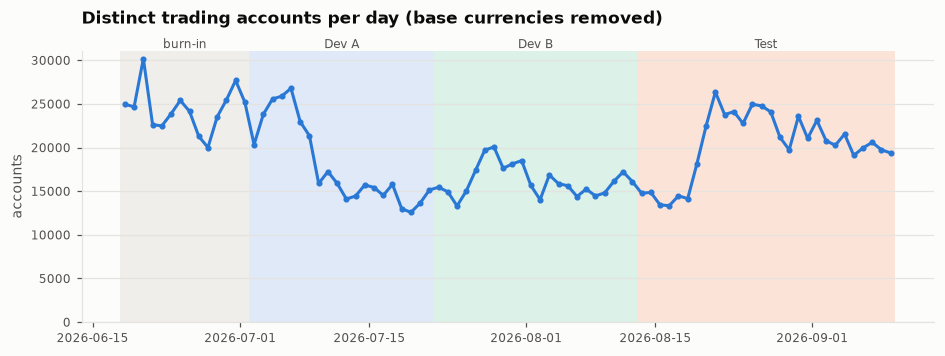

,legs,users
min,"83,427.000","12,576.000"
50%,"115,660.000","19,534.500"
max,"185,958.000","30,174.000"


In [9]:
daily = legs.groupby(legs["timestamp"].dt.floor("D")).agg(legs=("user", "size"), users=("user", "nunique"))
periods = {
    "burn-in": (td.DATA_START, td.BURN_IN_END),
    "Dev A": (td.BURN_IN_END, pc.DEV_B_START),
    "Dev B": (pc.DEV_B_START, pc.TEST_START),
    "Test": (pc.TEST_START, td.DATA_END),
}

fig, ax = plt.subplots(figsize=(10, 3.2))
plots.shade_periods(ax, periods)
ax.plot(daily.index + pd.Timedelta(hours=12), daily["users"], color=plots.SERIES[0], marker="o", markersize=3)
ax.set_title("Distinct trading accounts per day (base currencies removed)", pad=18)
ax.set_ylabel("accounts")
ax.set_ylim(bottom=0)
plt.show()
daily.describe().loc[["min", "50%", "max"]]

## 5. Descriptive statistics of the 12 weeks

The same quantities as Table 4 of the project plan, which were measured on the 14 days of the feasibility study.
The interaction is binary: a user *traded* a token, however often.

In [10]:
pairs = legs.drop_duplicates(["user", "token"])
tokens_per_user = pairs.groupby("user").size()
users_per_token = pairs.groupby("token").size()

density = len(pairs) / (len(tokens_per_user) * len(users_per_token))
table4 = pd.Series({
    "Users with at least one token": f"{len(tokens_per_user):,}",
    "Tokens": f"{len(users_per_token):,}",
    "Median tokens per user": f"{tokens_per_user.median():g}",
    "Users with at least 2 tokens": f"{(tokens_per_user >= 2).sum():,}",
    "Users with at least 5 tokens": f"{(tokens_per_user >= 5).sum():,}",
    "Tokens with at least 5 users": f"{(users_per_token >= 5).sum():,}",
    "Tokens with at least 100 users": f"{(users_per_token >= 100).sum():,}",
    "Share of buys among the legs": f"{(legs['side'] == 'buy').mean():.1%}",
    "Share of user-token cells filled": f"{density:.4%}",
})  # fmt: skip
table4.to_frame("12 weeks")

,12 weeks
Users with at least one token,"618,812"
Tokens,"57,411"
Median tokens per user,1
Users with at least 2 tokens,"201,427"
Users with at least 5 tokens,"49,405"
Tokens with at least 5 users,"17,787"
Tokens with at least 100 users,"2,124"
Share of buys among the legs,51.1%
Share of user-token cells filled,0.0051%


## Reading

- **The data is complete and clean.** 609 chunks without gaps; no duplicate or missing values; at least 99.985% of
  the swaps of every week are on pools whose tokens are known. The one flagged week is explained in section 2.
- **It covers the plan's dates exactly:** the first leg is 11 seconds after 18 June 00:00, the last one second
  before 10 September 00:00.
- **The base currencies are the same three as in the feasibility study**, with similar shares (WETH 80%, USDC 39%,
  USDT 24% of burn-in users, against 81%, 40%, 29%), and the gap to the fourth token (6.3%) is as wide. Removing
  them more than halves the data: 22.6 to 10.0 million legs.
- **The structure is the one the plan was built on, at a larger scale.** 618,812 accounts and 57,411 tokens. The
  median account still trades one token; 33% trade at least two (30% in the feasibility study) and 8% at least
  five (7%). Only 0.005% of the account-token table is filled.
- **Activity changes a lot over the 12 weeks:** from 12,600 to 30,200 accounts per day. It is lowest from mid-July
  to mid-August, which is most of Dev A and Dev B, and higher in the test period. Results must therefore always
  be compared point by point, never across periods, as the protocol does.